In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from src.logistic_scratch import ScratchLogisticRegression

In [2]:
df = pd.read_csv("../data/features.csv")

subset = df[df["mod"].isin(["BPSK", "QPSK"]) & (df["snr"] >= 0)]

X = subset.drop(columns=["mod", "snr"]).to_numpy()
y = (subset["mod"] == "QPSK").to_numpy().astype(int)

print(subset.shape)
print(subset["mod"].value_counts())

(20000, 14)
mod
QPSK    10000
BPSK    10000
Name: count, dtype: int64


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
scratch_model = ScratchLogisticRegression(learning_rate=0.5, n_iters=1000)
scratch_model.fit(X_train_scaled, y_train)

scratch_preds = scratch_model.predict(X_test_scaled)
scratch_accuracy = (scratch_preds == y_test).mean()
print(f"Scratch model test accuracy: {scratch_accuracy:.4f}")

Scratch model test accuracy: 0.8788


In [5]:
sklearn_model = LogisticRegression(C=np.inf, max_iter=5000)
sklearn_model.fit(X_train_scaled, y_train)

sklearn_accuracy = sklearn_model.score(X_test_scaled, y_test)
print(f"scikit-learn test accuracy: {sklearn_accuracy:.4f}")

comparison = pd.DataFrame({
    "feature": subset.drop(columns=["mod", "snr"]).columns,
    "scratch_weight": scratch_model.w,
    "sklearn_weight": sklearn_model.coef_[0],
})
comparison

scikit-learn test accuracy: 0.8792


,feature,scratch_weight,sklearn_weight
0,amplitude_std,-1.261843,-1.364399
1,amplitude_skew,-0.385018,-0.452616
2,amplitude_kurtosis,1.028370,0.939132
3,amplitude_peak_ratio,0.215895,0.348128
4,phase_mean,-0.047345,-0.047707
5,phase_std,0.930663,0.930027
6,phase_skew,-0.039731,-0.039783
7,phase_kurtosis,0.498928,0.499153
8,frequency_mean,-0.842187,-0.842348
9,frequency_std,-0.171149,-0.158812


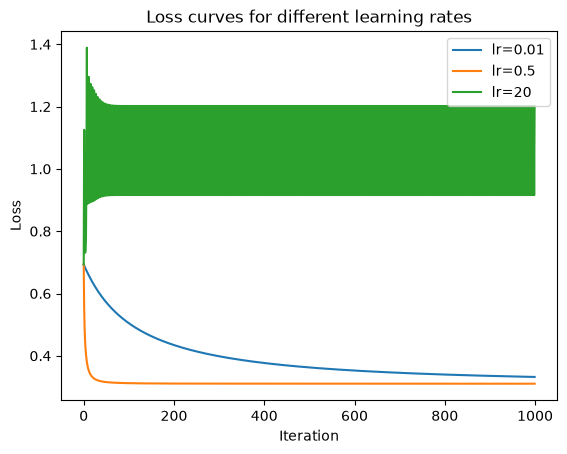

In [6]:
learning_rates = [0.01, 0.5, 20]

fig, ax = plt.subplots()
for lr in learning_rates:
    model = ScratchLogisticRegression(learning_rate=lr, n_iters=1000)
    model.fit(X_train_scaled, y_train)
    ax.plot(model.losses, label=f"lr={lr}")

ax.set_xlabel("Iteration")
ax.set_ylabel("Loss")
ax.set_title("Loss curves for different learning rates")
ax.legend()

fig.savefig("../figures/learning_rates.png")
plt.show()